# Data Analysis and Visualization(Extra plots)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10590 entries, 0 to 10589
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Airline                10590 non-null  object 
 1   Date_of_Journey        10590 non-null  object 
 2   Source                 10590 non-null  object 
 3   Destination            10590 non-null  object 
 4   Route                  10590 non-null  object 
 5   Dep_Time               10590 non-null  object 
 6   Arrival_Time           10590 non-null  object 
 7   Duration               10590 non-null  object 
 8   Total_Stops            10590 non-null  int64  
 9   Additional_Info        10590 non-null  object 
 10  Price                  10590 non-null  int64  
 11  Duration_Hour_Decimal  10590 non-null  float64
 12  Journey_Date           10590 non-null  object 
 13  Arrival_Date           10590 non-null  object 
dtypes: float64(1), int64(2), object(11)
memory usage: 1.1+

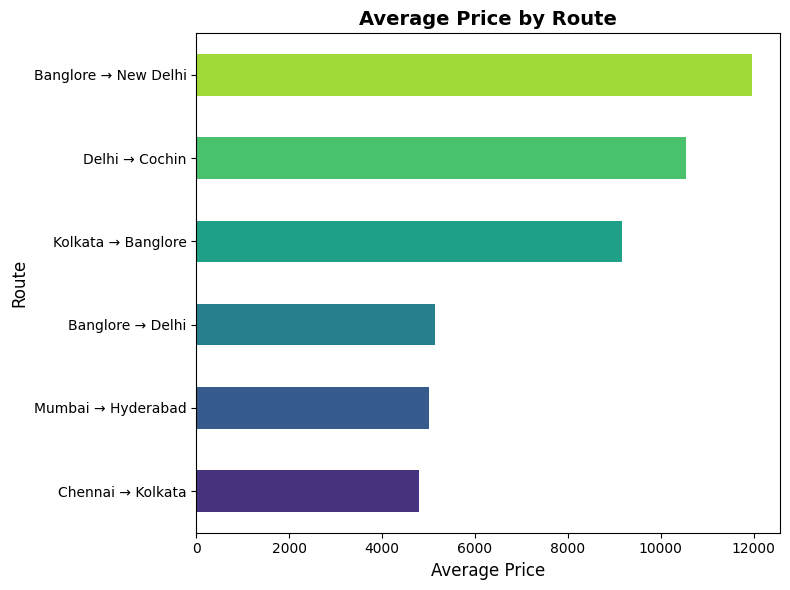

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Duration_Hour_Decimal,Journey_Date,Arrival_Date
0,Air India,1/05/2019,Kolkata,Banglore,Kolkata → Banglore,05:50,13:15,7h 25m,2,No info,7662,7.416667,2019-05-01,2019-05-01
1,Jet Airways,9/06/2019,Delhi,Cochin,Delhi → Cochin,09:25,04:25 10 Jun,19h,2,No info,13882,19.000000,2019-06-09,2019-06-10
2,IndiGo,12/05/2019,Kolkata,Banglore,Kolkata → Banglore,18:05,23:30,5h 25m,1,No info,6218,5.416667,2019-05-12,2019-05-12
3,IndiGo,01/03/2019,Banglore,New Delhi,Banglore → New Delhi,16:50,21:35,4h 45m,1,No info,13302,4.750000,2019-03-01,2019-03-01
4,SpiceJet,24/06/2019,Kolkata,Banglore,Kolkata → Banglore,09:00,11:25,2h 25m,0,No info,3873,2.416667,2019-06-24,2019-06-24


In [6]:
#Plot 1

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load and clean data
df = pd.read_csv("Flight.csv")
df.info()
df.isnull().sum()  # Check missing values
df.dropna(inplace=True)  # Remove rows with missing values

# Create 'Route' column
df['Route'] = df['Source'] + " → " + df['Destination']

# Compute average price per route
route_avg = df.groupby('Route')['Price'].mean().sort_values()

# Create a color palette based on number of routes
colors = sns.color_palette("viridis", len(route_avg))  # or try: "magma", "plasma", "coolwarm"

# Plot
plt.figure(figsize=(8, 6))
route_avg.plot(kind='barh', color=colors)

plt.title("Average Price by Route", fontsize=14, weight='bold')
plt.xlabel("Average Price", fontsize=12)
plt.ylabel("Route", fontsize=12)
plt.tight_layout()
plt.show()

df.head()


## Analysis of plot 1
The code performs an exploratory data analysis on flight pricing data by first loading and cleaning the dataset, removing any rows with missing values. It then creates a new 'Route' feature by combining the 'Source' and 'Destination' columns to represent flight paths. Next, it calculates the average flight price for each unique route and sorts these values. Finally, it visualizes this information with a horizontal bar plot, using a color palette to distinguish different routes, allowing easy comparison of average prices across various flight routes.

C:\Users\Owais\AppData\Local\Temp\ipykernel_12424\1634394153.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Journey_day', y='Price', data=df, order=day_order, palette='Set2')  # Try 'Set3', 'Pastel1', or 'husl'


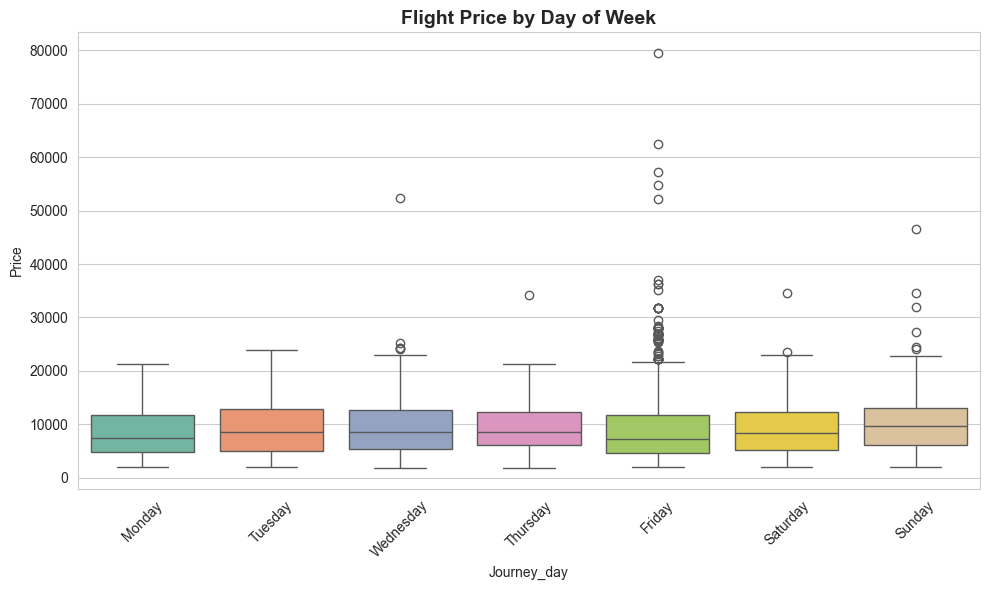

In [9]:
#Plot 2


# Extract day of week
df['Journey_day'] = pd.to_datetime(df['Date_of_Journey'],dayfirst=True, errors='coerce').dt.day_name()

# Optional: Order the days for better readability
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Set plot style
sns.set_style("whitegrid")

# Create boxplot with a colorful palette
plt.figure(figsize=(10, 6))
sns.boxplot(x='Journey_day', y='Price', data=df, order=day_order, palette='Set2')  # Try 'Set3', 'Pastel1', or 'husl'

plt.title("Flight Price by Day of Week", fontsize=14, weight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Analysis of plot 2
This code analyzes how flight prices vary across different days of the week by first extracting the day name from the 'Date_of_Journey' column and creating a new 'Journey_day' feature. It then visualizes the distribution of flight prices for each weekday using a boxplot, ordered from Monday to Sunday for clarity. The boxplot highlights price variations, medians, and potential outliers by day, helping to identify patterns or trends in pricing depending on the day of travel.

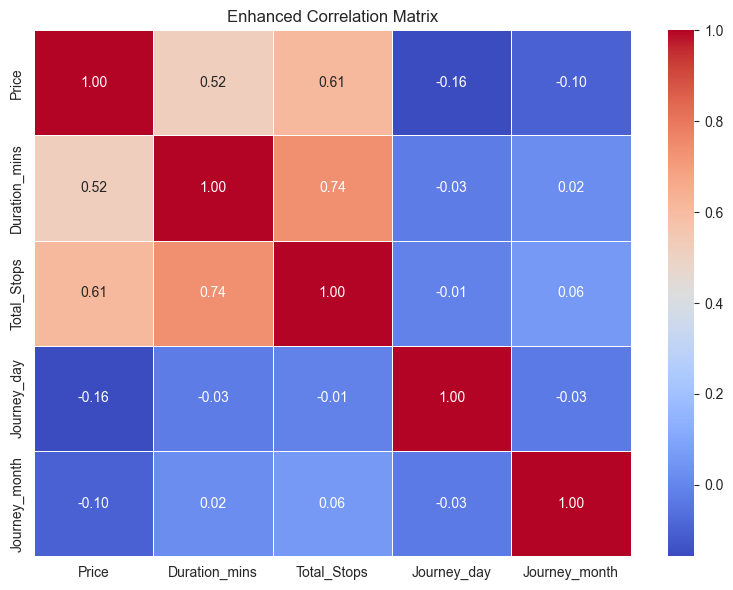

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Clean Duration format
df['Duration'] = df['Duration'].str.replace('h', 'h ').str.replace('m', 'm ').str.strip()

# Convert Duration to minutes
def convert_to_minutes(duration):
    total = 0
    for part in duration.split():
        if 'h' in part:
            total += int(part.replace('h', '')) * 60
        elif 'm' in part:
            total += int(part.replace('m', ''))
    return total

df['Duration_mins'] = df['Duration'].apply(convert_to_minutes)

# Convert Total_Stops to numeric
df['Total_Stops'] = df['Total_Stops'].replace({
    'non-stop': 0, '1 stop': 1, '2 stops': 2,
    '3 stops': 3, '4 stops': 4
}).astype(float)

# Fix: Convert Date_of_Journey to datetime with dayfirst=True
df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'], dayfirst=True)

# Extract numerical day and month
df['Journey_day'] = df['Date_of_Journey'].dt.day
df['Journey_month'] = df['Date_of_Journey'].dt.month

# Compute correlation matrix
corr = df[['Price', 'Duration_mins', 'Total_Stops', 'Journey_day', 'Journey_month']].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Enhanced Correlation Matrix")
plt.tight_layout()
plt.show()


## Analysis of plot 3
This code transforms and prepares several features for a deeper numerical analysis of factors influencing flight prices. It first converts the 'Duration' column from a mixed string format (e.g., "2h 30m") into a total duration in minutes, enabling quantitative analysis. It then maps the categorical 'Total_Stops' column to numeric values representing the number of stops for each flight. Additionally, it extracts the day and month from the 'Date_of_Journey' as numeric features to capture temporal effects.

Using these processed numerical variables, the code calculates the correlation matrix to quantify relationships between flight price, duration, number of stops, and journey timing (day and month). This correlation matrix is then visualized as a heatmap, providing an easy-to-interpret overview of how strongly each factor is linearly related to flight prices. This analysis helps identify which features most impact pricing, such as whether longer durations or more stops are associated with higher costs, and if timing (day or month) plays a significant role.